In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

#### 데이터 불러오기

In [3]:
df = pd.read_csv("../data/processed/tracks_with_clusters.csv")

print(df.shape)
df.head()

(76630, 20)


,track_id,track_name,artists,album_name,track_genre,duration_ms,popularity,danceability,energy,tempo,acousticness,instrumentalness,valence,mood,mood_score,mood_gap,cluster,mood_cluster,pca_1,pca_2
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Gen Hoshino,Comedy,acoustic,230666,73,0.676,0.461,87.917,0.032,0.000,0.715,romantic,0.595,0.001,2,romantic_2,0.576,1.241
1,4qPNDBW1i3p13qLCt0Ki3A,Ghost - Acoustic,Ben Woodward,Ghost (Acoustic),acoustic,149610,55,0.420,0.166,77.489,0.924,0.000,0.267,chill,0.918,0.071,0,chill_0,-2.672,1.213
2,1iJBSr7s7jYXzM8EGcbK5b,To Begin Again,Ingrid Michaelson;ZAYN,To Begin Again,acoustic,210826,57,0.438,0.359,76.332,0.210,0.000,0.120,sad,0.828,0.055,0,sad_0,-1.402,-0.087
3,6lfxq3CG4xtTiEg7opyCyx,Can't Help Falling In Love,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,acoustic,201933,71,0.266,0.060,181.740,0.905,0.000,0.143,dreamy,0.831,0.001,2,dreamy_2,-2.534,-0.581
4,5vjLSffimiIP26QG5WcN2K,Hold On,Chord Overstreet,Hold On,acoustic,198853,82,0.618,0.443,119.949,0.469,0.000,0.167,sad,0.767,0.138,1,sad_1,-0.837,0.224


In [4]:
features = ["danceability", "energy", "tempo", "acousticness", "instrumentalness", "valence"]

In [5]:
print(df["mood"].value_counts())

mood
happy        21405
energetic    16643
sad          15354
chill         7644
focus         6456
romantic      5051
dreamy        4077
Name: count, dtype: int64


In [6]:
print(df["cluster"].value_counts().sort_index())

cluster
0    36850
1    26055
2    13725
Name: count, dtype: int64


In [7]:
df[["track_name", "artists", "track_genre", "mood", "cluster", "mood_cluster"]].head(10)

,track_name,artists,track_genre,mood,cluster,mood_cluster
0,Comedy,Gen Hoshino,acoustic,romantic,2,romantic_2
1,Ghost - Acoustic,Ben Woodward,acoustic,chill,0,chill_0
2,To Begin Again,Ingrid Michaelson;ZAYN,acoustic,sad,0,sad_0
3,Can't Help Falling In Love,Kina Grannis,acoustic,dreamy,2,dreamy_2
4,Hold On,Chord Overstreet,acoustic,sad,1,sad_1
5,Days I Will Remember,Tyrone Wells,acoustic,romantic,1,romantic_1
6,Say Something,A Great Big World;Christina Aguilera,acoustic,sad,1,sad_1
7,I'm Yours,Jason Mraz,acoustic,happy,1,happy_1
8,Lucky,Jason Mraz;Colbie Caillat,acoustic,romantic,0,romantic_0
9,Hunger,Ross Copperman,acoustic,sad,0,sad_0


#### Feature 표준화

03에서 저장한 scaler 사용

In [8]:
scaler = joblib.load("../models/scaler.pkl")

scaled_values = scaler.transform(df[features])

scaled_df = pd.DataFrame(scaled_values, columns=features, index=df.index)

scaled_df.head()

,danceability,energy,tempo,acousticness,instrumentalness,valence
0,0.657,-0.684,-1.153,-0.886,-0.525,0.934
1,-0.822,-1.831,-1.501,1.745,-0.525,-0.783
2,-0.718,-1.080,-1.540,-0.361,-0.525,-1.347
3,-1.712,-2.244,1.982,1.689,-0.525,-1.258
4,0.322,-0.754,-0.083,0.403,-0.525,-1.167


#### 곡 검색

In [9]:
def search_tracks(keyword, limit=20):
    keyword = str(keyword).strip().casefold()

    result = df[
        df["track_name"].astype(str).str.casefold().str.contains(keyword, na=False)
        | df["artists"].astype(str).str.casefold().str.contains(keyword, na=False)
    ].copy()

    columns = ["track_name", "artists", "track_genre", "mood", "cluster"]

    return result[columns].head(limit)

In [10]:
search_tracks("love")

,track_name,artists,track_genre,mood,cluster
3,Can't Help Falling In Love,Kina Grannis,acoustic,dreamy,2
15,Falling in Love at a Coffee Shop,Landon Pigg,acoustic,sad,0
16,ily (i love you baby),Andrew Foy;Renee Foy,acoustic,chill,0
46,And I Love Her,Kurt Cobain,acoustic,dreamy,1
65,Please Don't Say You Love Me,Gabrielle Aplin,acoustic,chill,0
83,Can’t Help Falling in Love,Boyce Avenue,acoustic,sad,1
91,I Was Born To Love You,Ray LaMontagne;Sierra Ferrell,acoustic,sad,1
92,Only Love Can Hurt Like This,Meg Birch,acoustic,sad,1
99,Love Like This,Ben Rector,acoustic,sad,1
111,Make You Feel My Love,JJ Heller,acoustic,sad,1


In [11]:
search_tracks("coldplay")

,track_name,artists,track_genre,mood,cluster
15911,Something Just Like This,The Chainsmokers;Coldplay,dance,sad,0
39162,Coldplay,Lizzo,hip-hop,happy,1
57585,Hymn for the Weekend,Coldplay,pop,chill,1
57727,Christmas Lights,Coldplay,pop,sad,0
57728,A Sky Full of Stars - Hardwell Remix,Coldplay;Geoff Swan;Hardwell;Mark 'Spike' Stent,pop,sad,0
57741,Yellow,Coldplay,pop,sad,0
57743,Green Eyes,Coldplay,pop,sad,1
57744,The Scientist,Coldplay,pop,sad,1
57745,Higher Power,Coldplay,pop,energetic,1
57746,Everyday Life,Coldplay,pop,dreamy,0


#### Seed 선택

In [12]:
seed_index = 0

seed = df.loc[seed_index]

print("곡명:", seed["track_name"])
print("아티스트:", seed["artists"])
print("장르:", seed["track_genre"])
print("무드:", seed["mood"])
print("군집:", seed["cluster"])

곡명: Comedy
아티스트: Gen Hoshino
장르: acoustic
무드: romantic
군집: 2


In [13]:
seed_features = df.loc[seed_index, features]

seed_features

danceability        0.676
energy              0.461
tempo              87.917
acousticness        0.032
instrumentalness    0.000
valence             0.715
Name: 0, dtype: float64

In [14]:
seed_scaled = scaled_df.loc[seed_index, features].to_numpy().reshape(1, -1)

seed_scaled

array([[ 0.65691861, -0.68383667, -1.15274223, -0.88604826, -0.52518059,
         0.93369639]])

#### 같은 무드·군집 후보에서 유사도 계산

In [15]:
same_mood = df[df["mood"] == seed["mood"]].copy()

print("같은 무드 곡 수:", len(same_mood))

같은 무드 곡 수: 5051


In [16]:
same_mood_cluster = df[(df["mood"] == seed["mood"]) & (df["cluster"] == seed["cluster"])].copy()

print("같은 무드·같은 군집 곡 수:", len(same_mood_cluster))

같은 무드·같은 군집 곡 수: 1848


In [17]:
same_mood_cluster["track_genre"].value_counts().head(10)

track_genre
comedy         211
pagode         111
samba           94
sertanejo       59
pop-film        57
rock-n-roll     57
mpb             56
salsa           56
k-pop           41
bluegrass       39
Name: count, dtype: int64

In [18]:
candidate_indices = same_mood_cluster.index

candidate_matrix = scaled_df.loc[candidate_indices, features].to_numpy()

similarities = cosine_similarity(seed_scaled, candidate_matrix).flatten()

same_mood_cluster["similarity"] = similarities

same_mood_cluster = same_mood_cluster.drop(index=seed_index, errors="ignore").sort_values(
    "similarity", ascending=False
)

same_mood_cluster[["track_name", "artists", "track_genre", "mood", "cluster", "similarity"]].head(
    20
)

,track_name,artists,track_genre,mood,cluster,similarity
58297,Yacht Dance - 2001 Remaster,XTC,power-pop,romantic,2,0.994
67617,Un Elefante en un Pesebre,Los Caligaris,ska,romantic,2,0.992
12442,Link Up,Kid Travis,chill,romantic,2,0.987
45318,プロタゴニスト,Dempagumi.Inc,j-idol,romantic,2,0.980
8957,Octopus's Garden - Remastered 2009,The Beatles,british,romantic,2,0.976
15487,Songs About You,Brett Eldredge,country,romantic,2,0.974
60831,O Trem,RZO,r-n-b,romantic,2,0.973
69555,Si No Está Usted,Natalia Jiménez,spanish,romantic,2,0.971
16938,Nuh Dress Like Girl,Harry Toddler,dancehall,romantic,2,0.969
75472,Paramparça 2017,Teoman,turkish,romantic,2,0.968


In [19]:
mood_indices = same_mood.index

mood_matrix = scaled_df.loc[mood_indices, features].to_numpy()

mood_similarities = cosine_similarity(seed_scaled, mood_matrix).flatten()

same_mood["similarity"] = mood_similarities

same_mood = same_mood.drop(index=seed_index, errors="ignore").sort_values(
    "similarity", ascending=False
)

same_mood[["track_name", "artists", "track_genre", "mood", "cluster", "similarity"]].head(20)

,track_name,artists,track_genre,mood,cluster,similarity
58297,Yacht Dance - 2001 Remaster,XTC,power-pop,romantic,2,0.994
67617,Un Elefante en un Pesebre,Los Caligaris,ska,romantic,2,0.992
12442,Link Up,Kid Travis,chill,romantic,2,0.987
45318,プロタゴニスト,Dempagumi.Inc,j-idol,romantic,2,0.980
8957,Octopus's Garden - Remastered 2009,The Beatles,british,romantic,2,0.976
28177,Ela Faz Horrores Com a Xrc Dela X Cala a Boca,Mc Souza;MC MENOR MT,funk,romantic,1,0.976
15487,Songs About You,Brett Eldredge,country,romantic,2,0.974
48301,The Walmart Shuffle,Cupid,kids,romantic,1,0.974
60831,O Trem,RZO,r-n-b,romantic,2,0.973
69555,Si No Está Usted,Natalia Jiménez,spanish,romantic,2,0.971


#### 추천 함수

In [20]:
def recommend_by_seed(df, scaled_df, seed_index, count=20, use_cluster=True):
    seed = df.loc[seed_index]

    if use_cluster:
        candidates = df[(df["mood"] == seed["mood"]) & (df["cluster"] == seed["cluster"])].copy()
    else:
        candidates = df[df["mood"] == seed["mood"]].copy()

    candidates = candidates.drop(index=seed_index, errors="ignore")

    seed_vector = scaled_df.loc[seed_index, features].to_numpy().reshape(1, -1)

    candidate_vectors = scaled_df.loc[candidates.index, features].to_numpy()

    candidates["similarity"] = cosine_similarity(seed_vector, candidate_vectors).flatten()

    return candidates.sort_values("similarity", ascending=False).head(count)

In [21]:
recommendations = recommend_by_seed(
    df=df, scaled_df=scaled_df, seed_index=seed_index, count=50, use_cluster=True
)

recommendations[["track_name", "artists", "track_genre", "mood", "cluster", "similarity"]].head(20)

,track_name,artists,track_genre,mood,cluster,similarity
58297,Yacht Dance - 2001 Remaster,XTC,power-pop,romantic,2,0.994
67617,Un Elefante en un Pesebre,Los Caligaris,ska,romantic,2,0.992
12442,Link Up,Kid Travis,chill,romantic,2,0.987
45318,プロタゴニスト,Dempagumi.Inc,j-idol,romantic,2,0.980
8957,Octopus's Garden - Remastered 2009,The Beatles,british,romantic,2,0.976
15487,Songs About You,Brett Eldredge,country,romantic,2,0.974
60831,O Trem,RZO,r-n-b,romantic,2,0.973
69555,Si No Está Usted,Natalia Jiménez,spanish,romantic,2,0.971
16938,Nuh Dress Like Girl,Harry Toddler,dancehall,romantic,2,0.969
75472,Paramparça 2017,Teoman,turkish,romantic,2,0.968


#### 같은 아티스트 반복 제한

In [22]:
def limit_artist_repetition(recommendations, count=20, max_per_artist=2):
    selected = []
    artist_counts = {}

    for index, row in recommendations.iterrows():
        artist = row["artists"]
        current_count = artist_counts.get(artist, 0)

        if current_count >= max_per_artist:
            continue

        selected.append(index)
        artist_counts[artist] = current_count + 1

        if len(selected) >= count:
            break

    return recommendations.loc[selected]

In [23]:
recommendations = limit_artist_repetition(recommendations, count=20, max_per_artist=2)

recommendations[["track_name", "artists", "track_genre", "mood", "cluster", "similarity"]]

,track_name,artists,track_genre,mood,cluster,similarity
58297,Yacht Dance - 2001 Remaster,XTC,power-pop,romantic,2,0.994
67617,Un Elefante en un Pesebre,Los Caligaris,ska,romantic,2,0.992
12442,Link Up,Kid Travis,chill,romantic,2,0.987
45318,プロタゴニスト,Dempagumi.Inc,j-idol,romantic,2,0.980
8957,Octopus's Garden - Remastered 2009,The Beatles,british,romantic,2,0.976
15487,Songs About You,Brett Eldredge,country,romantic,2,0.974
60831,O Trem,RZO,r-n-b,romantic,2,0.973
69555,Si No Está Usted,Natalia Jiménez,spanish,romantic,2,0.971
16938,Nuh Dress Like Girl,Harry Toddler,dancehall,romantic,2,0.969
75472,Paramparça 2017,Teoman,turkish,romantic,2,0.968


In [24]:
recommendations["track_genre"].value_counts()

track_genre
dancehall    3
mpb          2
power-pop    1
ska          1
chill        1
j-idol       1
british      1
country      1
r-n-b        1
spanish      1
turkish      1
funk         1
latino       1
salsa        1
soul         1
garage       1
j-dance      1
Name: count, dtype: int64

In [25]:
recommendations["artists"].value_counts()

artists
XTC                           1
Los Caligaris                 1
Kid Travis                    1
Dempagumi.Inc                 1
The Beatles                   1
Brett Eldredge                1
RZO                           1
Natalia Jiménez               1
Harry Toddler                 1
Teoman                        1
Zimbra                        1
Syster Sol                    1
Os Paralamas Do Sucesso       1
MC Igão;MC Meno K;Dj Chulo    1
Jairo Vera                    1
La Sonora Dinamita            1
The Staple Singers            1
General Knas;Kapten Röd       1
Shola Ama                     1
AMARIA BB;Skillibeng          1
Name: count, dtype: int64

#### Seed와 추천곡 Feature 비교

In [26]:
feature_comparison = recommendations[features].mean().to_frame("recommendation_mean")

feature_comparison["seed"] = seed_features

feature_comparison

,recommendation_mean,seed
danceability,0.658,0.676
energy,0.515,0.461
tempo,90.319,87.917
acousticness,0.131,0.032
instrumentalness,0.010,0.000
valence,0.710,0.715


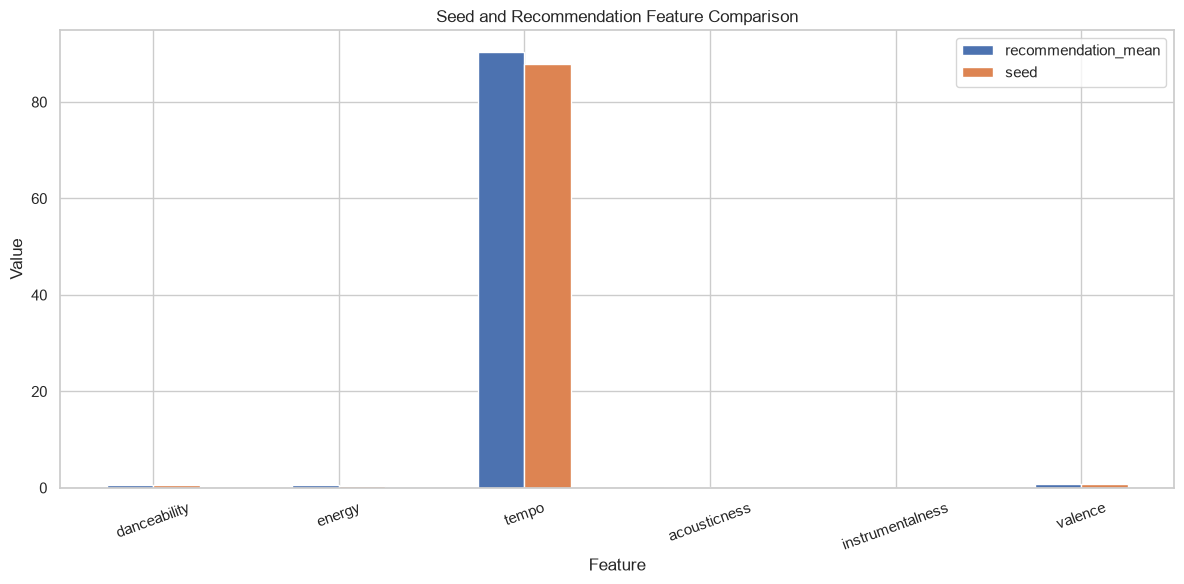

In [27]:
feature_comparison.plot(kind="bar", figsize=(12, 6))

plt.title("Seed and Recommendation Feature Comparison")
plt.xlabel("Feature")
plt.ylabel("Value")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
recommendation_features = pd.concat(
    [
        df.loc[[seed_index], features].assign(type="Seed"),
        recommendations[features].assign(type="Recommendation"),
    ]
)

recommendation_features

,danceability,energy,tempo,acousticness,instrumentalness,valence,type
0,0.676,0.461,87.917,0.032,0.000,0.715,Seed
58297,0.656,0.477,97.375,0.110,0.000,0.691,Recommendation
67617,0.675,0.502,97.014,0.127,0.000,0.673,Recommendation
12442,0.703,0.469,77.012,0.080,0.000,0.762,Recommendation
45318,0.657,0.573,96.003,0.128,0.000,0.649,Recommendation
8957,0.626,0.512,92.225,0.155,0.000,0.730,Recommendation
15487,0.649,0.558,89.988,0.147,0.000,0.635,Recommendation
60831,0.631,0.474,76.765,0.062,0.000,0.806,Recommendation
69555,0.637,0.570,102.922,0.184,0.000,0.649,Recommendation
16938,0.677,0.493,92.566,0.155,0.000,0.790,Recommendation


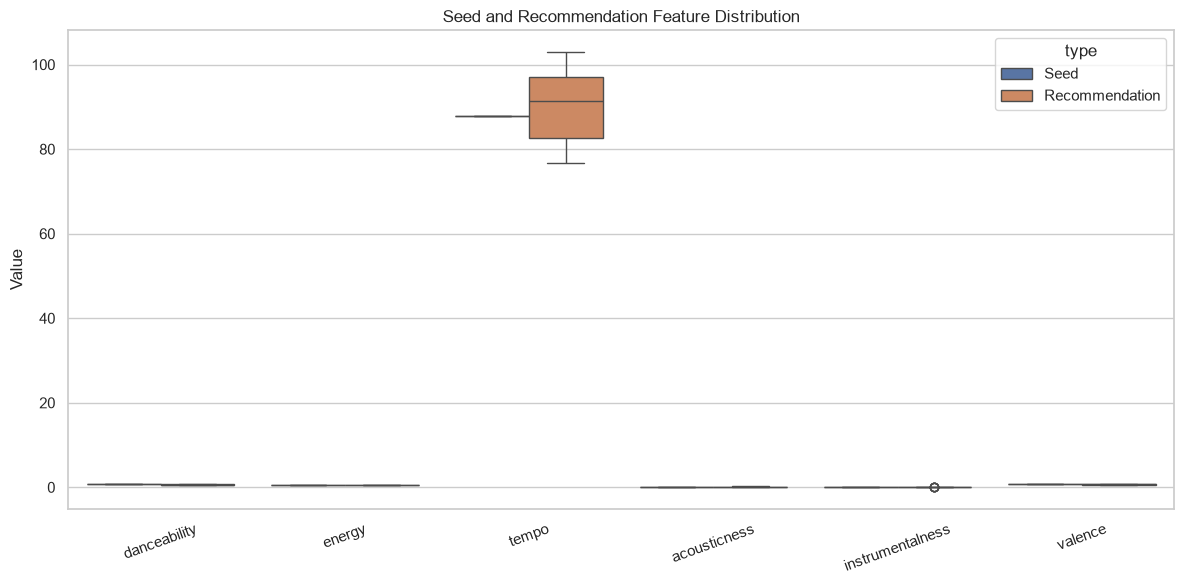

In [29]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=recommendation_features.melt(id_vars="type", var_name="feature", value_name="value"),
    x="feature",
    y="value",
    hue="type",
)

plt.title("Seed and Recommendation Feature Distribution")
plt.xlabel("")
plt.ylabel("Value")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [30]:
recommendations[["track_name", "artists", "similarity", "mood_score", "mood_gap"]].head(20)

,track_name,artists,similarity,mood_score,mood_gap
58297,Yacht Dance - 2001 Remaster,XTC,0.994,0.607,0.008
67617,Un Elefante en un Pesebre,Los Caligaris,0.992,0.600,0.010
12442,Link Up,Kid Travis,0.987,0.636,0.011
45318,プロタゴニスト,Dempagumi.Inc,0.980,0.583,0.010
8957,Octopus's Garden - Remastered 2009,The Beatles,0.976,0.636,0.013
15487,Songs About You,Brett Eldredge,0.974,0.607,0.004
60831,O Trem,RZO,0.973,0.648,0.008
69555,Si No Está Usted,Natalia Jiménez,0.971,0.589,0.015
16938,Nuh Dress Like Girl,Harry Toddler,0.969,0.638,0.019
75472,Paramparça 2017,Teoman,0.968,0.566,0.001


In [39]:
print("평균 유사도:", round(recommendations["similarity"].mean(), 3))
print("최저 유사도:", round(recommendations["similarity"].min(), 3))
print("최고 유사도:", round(recommendations["similarity"].max(), 3))

평균 유사도: 0.971
최저 유사도: 0.956
최고 유사도: 0.994


#### 다른 Seed로 테스트

무드별로 Seed를 하나씩 랜덤 선택

In [32]:
test_seed_indices = df.groupby("mood").sample(1, random_state=42).index.tolist()
test_seed_indices

[75424, 53286, 74108, 17726, 48371, 54983, 39735]

In [33]:
for test_index in test_seed_indices:
    test_seed = df.loc[test_index]

    print(f"\n{test_seed['track_name']} " f"- {test_seed['artists']}")
    print(f"무드: {test_seed['mood']}, " f"군집: {test_seed['cluster']}")

    result = recommend_by_seed(
        df=df, scaled_df=scaled_df, seed_index=test_index, count=5, use_cluster=True
    )

    display(result[["track_name", "artists", "similarity"]])


Korkuyu Al İçimden - Eskitilmiş Yaz
무드: chill, 군집: 1


,track_name,artists,similarity
19694,It's Been Too Long,The Whispers,0.997
54931,Não Tem pra Ninguém - Ao Vivo,Jeito Moleque,0.995
33135,Jumper - 1998 Edit,Third Eye Blind,0.991
791,Pop Virus,Gen Hoshino,0.987
10647,Sold On Love,Frankie Knuckles,0.985



10,000 Hours (Instrumental Version) - Laura Sullivan
무드: dreamy, 군집: 1


,track_name,artists,similarity
34284,Julia Florida,Agustín Barrios Mangoré;Emil Kjellbom,0.998
34380,Der Stieglitz,Agustín Amigó,0.997
20372,Some Day My Prince Will Come,The Circle Session Players,0.996
56343,Sunnebovals,Christian Peterson-Bergling,0.995
20924,"A Dream Is a Wish Your Heart Makes (from ""Cind...",Jartisto,0.994



Key To Happiness - Blastoyz;All In One;Dantra
무드: energetic, 군집: 2


...

,track_name,artists,similarity
15281,Best Day of My Life,Aunty Donna;Demi Lardner,0.997
48032,Bikers Shuffle - Radio W/Club Edition,Big Mucci,0.997
63930,Paper Heart,Ollie,0.997
51035,OTENAZI FASHION,ÖTENAZİ;Mavi,0.996
44263,Portmore City,Vybz Kartel;Top Secret Music,0.996



Rota Errada - Ao Vivo - Grupo Clareou
무드: romantic, 군집: 2


,track_name,artists,similarity
54802,O meu coração tem medo - Ao vivo,Ferrugem,0.994
71219,Alla våra minnen,Hov1,0.990
15175,Astronaut,Tom Papa,0.988
69662,Km 0,Brock Ansiolitiko,0.988
4614,Destiny Epic Rap,Zarcort,0.986



Stay Gold - Sarah Gayle Meech
무드: sad, 군집: 1


,track_name,artists,similarity
42051,I Don't Wanna Be Okay Without You,Charlie Burg,0.991
4239,Those Were the Days,Kupla,0.989
50477,思慕 - 電視劇《三生三世十里桃花》主人公人物曲,Yisa Yu,0.988
26048,Ele é,Os Arrais,0.982
46028,大きな玉ねぎの下で~はるかなる想い,Bakufu Slump,0.979


#### 군집 사용 여부 비교

In [34]:
with_cluster = recommend_by_seed(
    df=df, scaled_df=scaled_df, seed_index=seed_index, count=20, use_cluster=True
)

without_cluster = recommend_by_seed(
    df=df, scaled_df=scaled_df, seed_index=seed_index, count=20, use_cluster=False
)

In [35]:
comparison = pd.DataFrame(
    {
        "same_cluster": [
            with_cluster["similarity"].mean(),
            with_cluster["track_genre"].nunique(),
            with_cluster["artists"].nunique(),
        ],
        "same_mood": [
            without_cluster["similarity"].mean(),
            without_cluster["track_genre"].nunique(),
            without_cluster["artists"].nunique(),
        ],
    },
    index=["average_similarity", "genre_count", "artist_count"],
)

comparison

,same_cluster,same_mood
average_similarity,0.971,0.973
genre_count,17.000,17.000
artist_count,20.000,20.000


#### 결과 저장

In [36]:
output_columns = [
    "track_id",
    "track_name",
    "artists",
    "album_name",
    "track_genre",
    "popularity",
    "mood",
    "cluster",
    "mood_cluster",
    "similarity",
    "mood_score",
    "mood_gap",
]

recommendation_result = recommendations[output_columns].copy()

recommendation_result.insert(0, "order", range(1, len(recommendation_result) + 1))

recommendation_result.to_csv(
    "../reports/recommendation_result.csv", index=False, encoding="utf-8-sig"
)

recommendation_result

,order,track_id,track_name,artists,album_name,track_genre,popularity,mood,cluster,mood_cluster,similarity,mood_score,mood_gap
58297,1,0ccEtd9vMVSjm1R5y8R4xq,Yacht Dance - 2001 Remaster,XTC,English Settlement,power-pop,24,romantic,2,romantic_2,0.994,0.607,0.008
67617,2,422GpyFjvjVAcTqBQ9lzRT,Un Elefante en un Pesebre,Los Caligaris,Bailarín Apocalíptico,ska,43,romantic,2,romantic_2,0.992,0.600,0.010
12442,3,3KhW0VGRXLHruQQriH6gXJ,Link Up,Kid Travis,Link Up,chill,51,romantic,2,romantic_2,0.987,0.636,0.011
45318,4,7k5Fw4MZVCuiVjdB3bKPuR,プロタゴニスト,Dempagumi.Inc,DEMPARK!!!,j-idol,17,romantic,2,romantic_2,0.980,0.583,0.010
8957,5,0suLngfo7rJoetk7Ub6N8l,Octopus's Garden - Remastered 2009,The Beatles,Abbey Road (Remastered),british,63,romantic,2,romantic_2,0.976,0.636,0.013
15487,6,7A2YSo9trGZ9OlO7w2DICx,Songs About You,Brett Eldredge,New Country,country,0,romantic,2,romantic_2,0.974,0.607,0.004
60831,7,4FpVLn9ne4NDGo83yRTAIi,O Trem,RZO,RZO,r-n-b,42,romantic,2,romantic_2,0.973,0.648,0.008
69555,8,2FPFbWKK1SI2K8hwbs43qf,Si No Está Usted,Natalia Jiménez,Natalia Jiménez,spanish,32,romantic,2,romantic_2,0.971,0.589,0.015
16938,9,5CDZmaU9cwtVREa2kzDbZt,Nuh Dress Like Girl,Harry Toddler,Dancehall Xplosion '98,dancehall,26,romantic,2,romantic_2,0.969,0.638,0.019
75472,10,1lUbwJqUbNWungNXhrCVo9,Paramparça 2017,Teoman,Rock and Roll,turkish,40,romantic,2,romantic_2,0.968,0.566,0.001


In [37]:
all_recommendations = []

for test_index in df.sample(10, random_state=42).index:
    result = recommend_by_seed(
        df=df, scaled_df=scaled_df, seed_index=test_index, count=30, use_cluster=True
    )

    result = limit_artist_repetition(result, count=10, max_per_artist=2)

    result = result.copy()
    result["seed_index"] = test_index
    result["seed_track"] = df.loc[test_index, "track_name"]

    all_recommendations.append(result)

all_recommendations = pd.concat(all_recommendations, ignore_index=True)

all_recommendations.head()

,track_id,track_name,artists,album_name,track_genre,duration_ms,popularity,danceability,energy,tempo,acousticness,instrumentalness,valence,mood,mood_score,mood_gap,cluster,mood_cluster,pca_1,pca_2,similarity,seed_index,seed_track
0,40LYL1Z6xgCn5cBybo5K0D,It's Quiet Uptown,Renée Elise Goldsberry;Lin-Manuel Miranda;Phil...,Hamilton (Original Broadway Cast Recording),show-tunes,270171,62,0.484,0.187,129.753,0.796,0.000,0.227,sad,0.797,0.059,1,sad_1,-1.957,0.542,0.999,40019,Bartender's Blues (With James Taylor
1,2Oq7FNjSS7hdVYqWqmDcQr,"Fred Jones, Pt. 2",Ben Folds,Rockin' The Suburbs,piano,225933,31,0.486,0.166,131.854,0.894,0.000,0.239,sad,0.799,0.050,1,sad_1,-2.109,0.689,0.999,40019,Bartender's Blues (With James Taylor
2,1VPaIQKoYh4FzTn8DhGa5P,Canción Mixteca - Qué Lejos Estoy,Cuco Sánchez,Serie De Coleccion 15 Autenticos,guitar,186626,23,0.456,0.124,133.647,0.930,0.000,0.192,sad,0.831,0.068,1,sad_1,-2.370,0.590,0.999,40019,Bartender's Blues (With James Taylor
3,10TcaC8gPaLnUTixaAiSWC,"Слушайте, если хотите",Надежда Обухова,Великие исполнители россии: надежда обухова,romance,125133,0,0.465,0.082,131.712,0.989,0.000,0.190,sad,0.847,0.063,1,sad_1,-2.548,0.762,0.998,40019,Bartender's Blues (With James Taylor
4,18Tsg3JxjoeWGKtKtlwq1L,Unworthy of Your Love,Stephen Sondheim;Adam Chanler-Berat;Tavi Gevinson,Assassins (The 2022 Off-Broadway Cast Recording),show-tunes,217196,25,0.482,0.221,126.481,0.834,0.000,0.228,sad,0.800,0.050,1,sad_1,-1.970,0.575,0.997,40019,Bartender's Blues (With James Taylor


In [38]:
all_recommendations.to_csv(
    "../reports/recommendation_test_results.csv", index=False, encoding="utf-8-sig"
)

## 추천 결과

Seed는 Comedy - Gen Hoshino (romantic, 군집 2)로 테스트했다.

같은 무드·군집 후보 1,848곡 중 Cosine 유사도 상위 20곡을 추천, 평균 유사도는 0.971(0.956~0.994)

아티스트는 20명, 장르는 17개로 겹침이 적음

같은 군집으로 제한한 경우와 같은 무드 전체에서 찾은 경우의 차이가 거의 없다(0.971, 0.973). 군집 필터의 효과는 05에서 다시 확인

추천곡이 17개 장르에 퍼져 있어서 Feature가 비슷해도 실제 분위기는 다를 수 있음

다른 무드의 Seed 7개로도 추천이 정상적으로 나오는 것을 확인